In [1]:
# Base imports + list what's available locally
import numpy as np
import pandas as pd
import os

In [2]:
# Load the csv and take a look at the first rows
file_path = '../data/raw/predictive_maintenance.csv'
data = pd.read_csv(file_path)
data.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,No Failure
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,No Failure
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,No Failure
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,No Failure
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,No Failure


In [3]:
# General info, describe, and the class imbalance (this is the central problem of the project)
data.info()
data.describe()
data['Target'].value_counts(normalize=True)
data.isnull().sum()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Target                   10000 non-null  int64  
 9   Failure Type             10000 non-null  object 
dtypes: float64(3), int64(4), object(3)
memory usage: 781.4+ KB


UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Target                     0
Failure Type               0
dtype: int64

In [4]:
# y = what we want to predict
y = data['Target']

# X = everything except IDs, Type, and columns that would be "cheating" (Target, Failure Type)
columns_to_drop = ['UDI', 'Product ID', 'Type', 'Target', 'Failure Type']
X = data.drop(columns_to_drop, axis=1)

X.head()


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
0,298.1,308.6,1551,42.8,0
1,298.2,308.7,1408,46.3,3
2,298.1,308.5,1498,49.4,5
3,298.2,308.6,1433,39.5,7
4,298.2,308.7,1408,40.0,9


In [5]:
from sklearn.model_selection import train_test_split

# 80/20, fixed random_state to always get the same result
# stratify=y keeps the failure ratio equal in train and test
# (with <4% positive cases, skipping this can seriously skew the split)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train size: {X_train.shape[0]} rows")
print(f"Test size: {X_test.shape[0]} rows")

Train size: 8000 rows
Test size: 2000 rows


In [6]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)
print("Model trained.")

Model trained.


In [7]:
predictions = model.predict(X_test)

print("Predictions:", predictions[:5])
print("Actual:     ", y_test[:5].values)

Predictions: [0 0 0 0 0]
Actual:      [0 0 0 0 0]


In [8]:
from sklearn.metrics import accuracy_score, classification_report

accuracy = accuracy_score(y_test, predictions)
print(f"Accuracy: {accuracy * 100:.2f}%\n")

print(classification_report(y_test, predictions))

Accuracy: 98.50%

              precision    recall  f1-score   support

           0       0.99      1.00      0.99      1932
           1       0.90      0.63      0.74        68

    accuracy                           0.98      2000
   macro avg       0.94      0.81      0.87      2000
weighted avg       0.98      0.98      0.98      2000



In [9]:
# Second attempt: class_weight='balanced' instead of touching the data
balanced_model = RandomForestClassifier(random_state=42, class_weight='balanced')
balanced_model.fit(X_train, y_train)
print("Trained.\n")

balanced_predictions = balanced_model.predict(X_test)
print(classification_report(y_test, balanced_predictions))

Trained.

              precision    recall  f1-score   support

           0       0.99      1.00      0.99      1932
           1       0.89      0.57      0.70        68

    accuracy                           0.98      2000
   macro avg       0.94      0.79      0.84      2000
weighted avg       0.98      0.98      0.98      2000



In [10]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

# only on the train set - if you apply this before the split, you're leaking data
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_smote.value_counts())

Before SMOTE:
Target
0    7729
1     271
Name: count, dtype: int64

After SMOTE:
Target
0    7729
1    7729
Name: count, dtype: int64


In [11]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

# class_weight doesn't make sense here anymore, the classes are already balanced by SMOTE
final_model = RandomForestClassifier(random_state=42)
final_model.fit(X_train_smote, y_train_smote)
print("Trained with SMOTE data.\n")

# always evaluate on the original test set - SMOTE can't touch this
final_predictions = final_model.predict(X_test)
print(classification_report(y_test, final_predictions))

Trained with SMOTE data.

              precision    recall  f1-score   support

           0       0.99      0.96      0.98      1932
           1       0.43      0.78      0.56        68

    accuracy                           0.96      2000
   macro avg       0.71      0.87      0.77      2000
weighted avg       0.97      0.96      0.96      2000



In [12]:
from sklearn.metrics import roc_auc_score

# predict_proba instead of predict, to see the probability and not just the final decision
probabilities = final_model.predict_proba(X_test)[:, 1]

auc = roc_auc_score(y_test, probabilities)
print(f"AUC: {auc * 100:.2f}%")

AUC: 96.37%


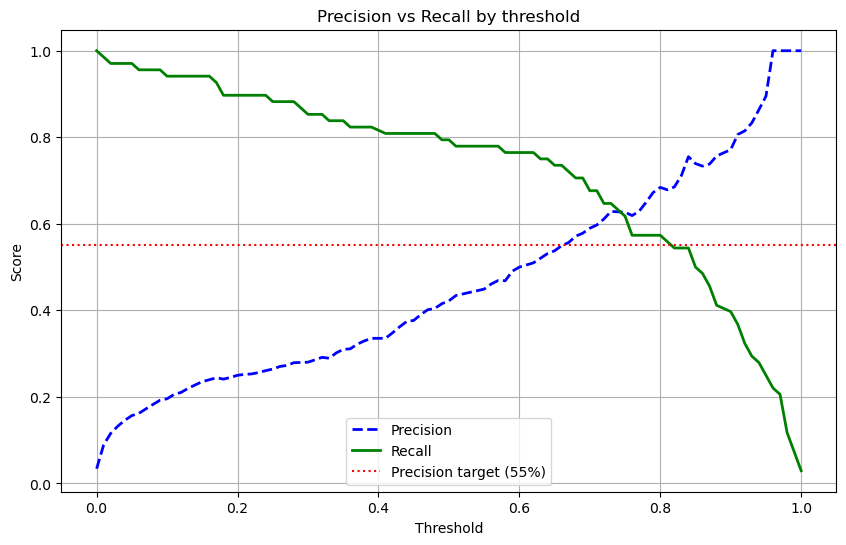

In [13]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve

probabilities = final_model.predict_proba(X_test)[:, 1]
precisions, recalls, thresholds = precision_recall_curve(y_test, probabilities)

plt.figure(figsize=(10, 6))
plt.plot(thresholds, precisions[:-1], 'b--', linewidth=2, label='Precision')
plt.plot(thresholds, recalls[:-1], 'g-', linewidth=2, label='Recall')
plt.axhline(y=0.55, color='r', linestyle=':', label='Precision target (55%)')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision vs Recall by threshold')
plt.legend(loc='best')
plt.grid(True)
plt.show()

In [14]:
from sklearn.metrics import confusion_matrix

def calculate_financial_result(y_true, y_pred):
    false_alarm_cost = -500
    breakdown_cost = -15000
    prevention_savings = 14000

    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

    print("--- Operational Report ---")
    print(f"False alarms: {fp}")
    print(f"Undetected failures: {fn}")
    print(f"Successful preventions: {tp}\n")

    money_lost_alarms = fp * false_alarm_cost
    money_lost_breakdowns = fn * breakdown_cost
    money_saved = tp * prevention_savings

    return money_lost_alarms + money_lost_breakdowns + money_saved

model_profit = calculate_financial_result(y_test, final_predictions)
print(f"Financial result: {model_profit} Euros")

--- Operational Report ---
False alarms: 69
Undetected failures: 15
Successful preventions: 53

Financial result: 482500 Euros


--- Overall feature importance ---


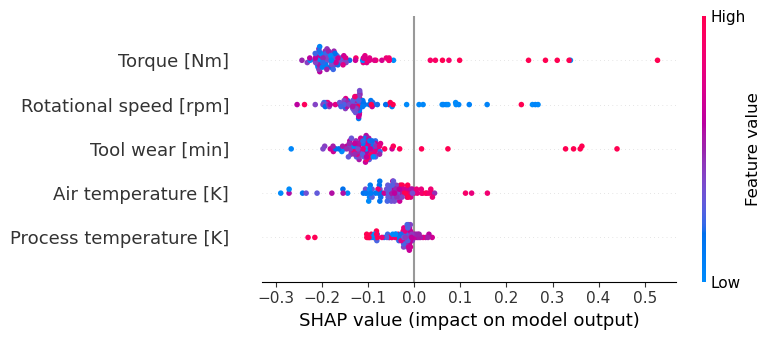


--- Explanation for machine 10 ---


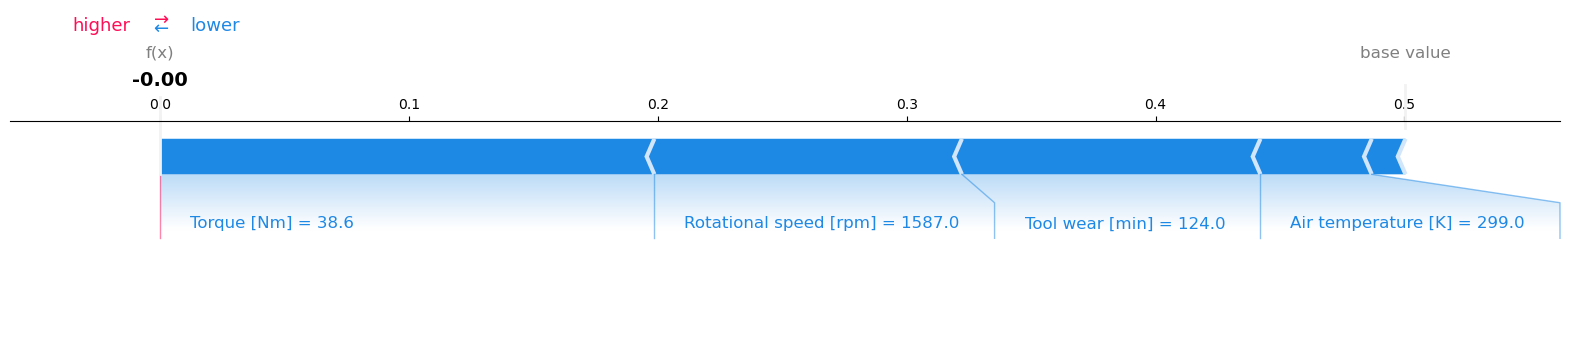

In [15]:
import shap

shap.initjs()
X_sample = X_test.iloc[:100]

explainer = shap.TreeExplainer(final_model)
shap_values = explainer.shap_values(X_sample)

# the shap_values format changes depending on the library version, hence the if/else
if isinstance(shap_values, list):
    failure_shap_values = shap_values[1]
else:
    failure_shap_values = shap_values[:, :, 1]

print("--- Overall feature importance ---")
shap.summary_plot(failure_shap_values, X_sample)

target_machine = 10
print(f"\n--- Explanation for machine {target_machine} ---")

if isinstance(explainer.expected_value, list) or isinstance(explainer.expected_value, np.ndarray):
    base_value = explainer.expected_value[1]
else:
    base_value = explainer.expected_value

shap.force_plot(base_value, failure_shap_values[target_machine], X_sample.iloc[target_machine], matplotlib=True)

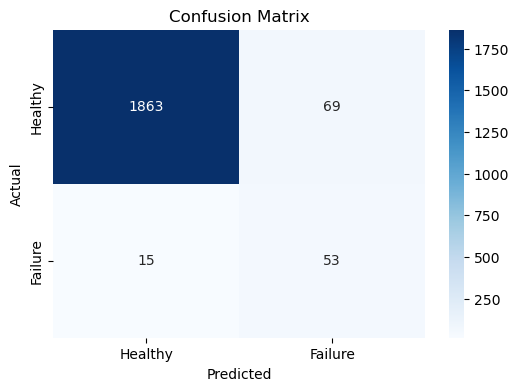

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

matrix = confusion_matrix(y_test, final_predictions)

plt.figure(figsize=(6, 4))
sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Healthy', 'Failure'],
            yticklabels=['Healthy', 'Failure'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

Idea: what if machines were split by criticality level?

In [ ]:
probabilities = final_model.predict_proba(X_test)[:, 1]

decision_table = X_test.copy()
decision_table['Type'] = data.loc[X_test.index, 'Type']
decision_table['Failure_Probability'] = probabilities
decision_table['Final_Decision'] = 0

# Type H (higher quality/cost) treated as the critical zone: lower threshold,
# because the cost of missing a failure here is higher
critical_threshold = 0.3
critical_zone_mask = decision_table['Type'] == 'H'
decision_table.loc[critical_zone_mask & (decision_table['Failure_Probability'] >= critical_threshold), 'Final_Decision'] = 1

# Rest of the factory (L/M): higher threshold, to avoid too many false alarms
normal_threshold = 0.8
rest_mask = decision_table['Type'] != 'H'
decision_table.loc[rest_mask & (decision_table['Failure_Probability'] >= normal_threshold), 'Final_Decision'] = 1

print("Alarms triggered by Type:")
print(decision_table.groupby('Type')['Final_Decision'].sum())

# If you want to apply this to a specific list of machines instead of a whole type,
# you can filter by Product ID the same way:
critical_machines = ['M14860', 'L47181', 'H35422']
critical_mask = data.loc[X_test.index, 'Product ID'].isin(critical_machines)
decision_table.loc[critical_mask.values & (decision_table['Failure_Probability'] >= critical_threshold), 'Final_Decision'] = 1

print(f"\nExtra alarms from the critical machines list alone: {critical_mask.sum()} machines in the sample")

Idea: what if we only had data from healthy machines?

In [ ]:
from sklearn.ensemble import IsolationForest

# train only on healthy data (Target == 0) - unsupervised, learns what "normal" looks like
healthy_training_data = data[data['Target'] == 0]
X_train_normal = healthy_training_data.drop(columns_to_drop, axis=1)

# contamination = expected % of anomalies
anomaly_detector = IsolationForest(random_state=42, contamination=0.03)
anomaly_detector.fit(X_train_normal)
print("Isolation Forest trained.")

# 1 = normal, -1 = anomaly (sklearn's odd convention, worth remembering)
raw_predictions = anomaly_detector.predict(X_test)
anomaly_final_predictions = np.where(raw_predictions == 1, 0, 1)

print("\nIsolation Forest report:")
print(classification_report(y_test, anomaly_final_predictions, zero_division=0))

Idea: what if we had the max RPM/temperature values per machine?

In [ ]:
max_observed_rpm = data['Rotational speed [rpm]'].max()
data['Rpm_Effort_Pct'] = data['Rotational speed [rpm]'] / max_observed_rpm

print("New variable created.")
data[['Rotational speed [rpm]', 'Rpm_Effort_Pct']].head()

In [ ]:
# Torque fatigue: high torque is only a problem if the tool is already worn
data['Torque_Fatigue'] = data['Torque [Nm]'] * data['Tool wear [min]']

# Thermal fatigue: accumulated temperature difference over the tool's wear
data['Temp_Diff'] = data['Process temperature [K]'] - data['Air temperature [K]']
data['Thermal_Fatigue'] = data['Temp_Diff'] * data['Tool wear [min]']

print("Fatigue columns created.")
data[['Torque [Nm]', 'Tool wear [min]', 'Torque_Fatigue', 'Thermal_Fatigue']].head()

In [ ]:
columns_to_drop_fe = ['UDI', 'Product ID', 'Type', 'Target', 'Failure Type']

y_fe = data['Target']
X_fe = data.drop(columns_to_drop_fe, axis=1)

X_train_fe, X_test_fe, y_train_fe, y_test_fe = train_test_split(
    X_fe, y_fe, test_size=0.2, random_state=42, stratify=y_fe
)

X_train_fe_smote, y_train_fe_smote = smote.fit_resample(X_train_fe, y_train_fe)

final_model_fe = RandomForestClassifier(random_state=42)
final_model_fe.fit(X_train_fe_smote, y_train_fe_smote)

final_predictions_fe = final_model_fe.predict(X_test_fe)

print("With fatigue features:")
print(classification_report(y_test_fe, final_predictions_fe))

print("\nWithout fatigue features (for comparison):")
print(classification_report(y_test, final_predictions))

In [ ]:
# simulated IoT sensor data
iot_data = pd.DataFrame({
    'Timestamp': ['2026-07-02 10:00:00', '2026-07-02 10:01:00', '2026-07-02 10:02:00', '2026-07-02 10:03:00', '2026-07-02 10:04:00'],
    'Temperature': [300.1, 302.5, 305.0, 310.2, 315.5]
})

iot_data['Timestamp'] = pd.to_datetime(iot_data['Timestamp'])
iot_data = iot_data.set_index('Timestamp')

# 3-minute rolling average
iot_data['Rolling_Temp_3min'] = iot_data['Temperature'].rolling(window='3min').mean()

print(iot_data)

Idea: what if we could classify the failure type, not just whether there's a failure?

In [ ]:
y_multiclass = data['Failure Type']

# drop Target AND Failure Type - otherwise the model can see the answer
columns_to_drop_multi = ['UDI', 'Product ID', 'Type', 'Target', 'Failure Type']
X_multiclass = data.drop(columns_to_drop_multi, axis=1)

# stratify matters even more here - some failure types have very few examples
X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X_multiclass, y_multiclass, test_size=0.2, random_state=42, stratify=y_multiclass
)

# balanced matters even more here - the few failures split across 5 types
multiclass_model = RandomForestClassifier(random_state=42, class_weight='balanced')
multiclass_model.fit(X_train_m, y_train_m)
print("Multiclass model trained.\n")

multiclass_predictions = multiclass_model.predict(X_test_m)

# zero_division=0 avoids warnings when a rare class gets no predictions
print(classification_report(y_test_m, multiclass_predictions, zero_division=0))